# 1. Research Question and Economic Motivation
Does topic specialization moderate the relationship between average liquidity consumption and overall trader profitability? Topic knowledge might help specialized traders identify opportunities when executing aggressively, but information advantages and beliefs are **not measured**. This is a proposed economic mechanism, not an established fact.

Define $P_i$ = `trader_ppv`, $L_i$ = `price_levels_per_transaction`, and $S_i$ = `largest_transformers_topic_share`. Estimate
$$P_i=\beta_0+\beta_1L_i+\beta_2S_i+\beta_3L_iS_i+\epsilon_i.$$
The liquidity slope is $\beta_1+\beta_3S_i$. The directional hypothesis is $H_0:\beta_3=0$ versus $H_1:\beta_3>0$. The **primary test is two-sided**, with a 95% confidence interval; the prespecified positive-direction one-sided test is supplemental. This observational notebook is not a causal design or registered confirmatory study.

# 2. Dataset Loading and Inspection
Run from the folder containing `data_no_imputation.parquet`. Dependencies: pandas, NumPy, Matplotlib, SciPy, statsmodels, pyarrow (or another Parquet engine), and IPython/Jupyter. All analysis state is initialized here. The Parquet file is only read.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
df = pd.read_parquet("data_no_imputation.parquet")
print('Dataset shape:', df.shape)
S, L, P = 'largest_transformers_topic_share', 'price_levels_per_transaction', 'trader_ppv'
ALT_S = 'largest_tags_topic_share'
controls = ['mean_tx_value', 'transactions_per_day', 'markets_per_day']
alt_execution = ['price_levels_consumed_vw', 'price_levels_vw_per_transaction', 'price_levels_per_volume']
required = ['trader', S, L, P, ALT_S, 'trader_pnl', 'transaction_count', 'trader_volume'] + controls + alt_execution
missing = sorted(set(required)-set(df.columns))
if missing:
    raise ValueError(f'Missing required columns: {missing}')
print('All required columns exist.')
display(pd.DataFrame({'dtype': df[required].dtypes.astype(str), 'missing': df[required].isna().sum()}))

Dataset shape: (524760, 41)
All required columns exist.


,dtype,missing
trader,string,0
largest_transformers_topic_share,float64,0
price_levels_per_transaction,float64,0
trader_ppv,float64,0
largest_tags_topic_share,float64,0
trader_pnl,float64,0
transaction_count,uint32,0
trader_volume,float64,0
mean_tx_value,float64,0
transactions_per_day,float64,0


# 3. Data Preparation
Create a separate working copy. Report duplicate trader IDs and their records, then stop for investigation rather than aggregate or delete them. Each sample excludes missing/infinite values only in its own required variables and transaction count. Unrelated missing values do not affect eligibility. Finite extremes are retained. Out-of-range specialization values trigger investigation rather than silent clipping.

In [2]:
working = df.copy(deep=True)
duplicated = working.trader.duplicated(keep=False)
print('Missing trader IDs:', int(working.trader.isna().sum()))
print('Rows with duplicated trader IDs:', int(duplicated.sum()))
if duplicated.any():
    display(working.loc[duplicated, required].sort_values('trader'))
if duplicated.any() or working.trader.isna().any():
    raise ValueError('Investigate trader identifiers before treating observations as independent traders.')
for col in required:
    if col != 'trader':
        working[col] = pd.to_numeric(working[col], errors='raise')
sample_audit = []
def sample_for(columns, threshold=100, label='Analysis'):
    cols = list(dict.fromkeys(['transaction_count'] + list(columns)))
    eligible = working.transaction_count.ge(threshold)
    finite = np.isfinite(working[cols].to_numpy(dtype=float, na_value=np.nan)).all(axis=1)
    data = working.loc[eligible & finite, cols].copy()
    for share in [S, ALT_S]:
        if share in data and not data[share].between(0,1).all():
            display(data.loc[~data[share].between(0,1)])
            raise ValueError(f'Invalid {share}: investigate without clipping.')
    report = {'analysis': label, 'threshold': threshold, 'original_n': len(working), 'after_threshold': int(eligible.sum()),
              'invalid_removed': int((eligible & ~finite).sum()), 'final_n': len(data)}
    sample_audit.append(report)
    display(pd.DataFrame([report]))
    if len(data) < 10:
        raise ValueError('Too few observations.')
    return data
primary = sample_for([S,L,P], label='Primary PPV')
print('Primary specialization bounds [0,1] verified.')

Missing trader IDs: 0
Rows with duplicated trader IDs: 0
Primary specialization bounds [0,1] verified.


,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Primary PPV,100,524760,21323,0,21323


# 4. Variable Definitions and Descriptive Statistics
Use specialization as largest-topic concentration, following the supplied definition. Available project files do not establish its activity denominator; it is not assumed to be a transaction share.

Use `price_levels_per_transaction` as the requested liquidity-consumption proxy, subject to its incomplete documentation. Values below one and zeros mean it should not be assumed to count all distinct levels crossed. Interpret slopes in **recorded proxy units**. Numeric reconstruction is not proof of economic meaning.

Liquidity consumption is not execution cost. Slippage requires a benchmark price, trade direction, and execution-price data. Depth, spreads, order size, and price increments also matter. More price levels consumed need not imply worse execution or information-driven trading.

Histograms and the scatter plot retain the full finite range. A symmetric-log scatter X-axis handles zeros and any negatives; it changes display spacing, not the primary raw-scale model.

Zero liquidity values: 1987
Negative liquidity values retained: 0
Proxy matches price_levels_consumed / count: 100.00%
Symmetric-log linear-region threshold: 0.00020816666666666683


,count,mean,std,min,1%,10%,25%,50%,75%,90%,99%,max,median,skewness
largest_transformers_topic_share,21323.0,0.550246,0.164972,0.174494,0.289324,0.375259,0.436208,0.514616,0.625753,0.789830,1.000000,1.000000,0.514616,1.032900
price_levels_per_transaction,21323.0,0.008054,0.015283,0.000000,0.000000,0.000002,0.000711,0.003722,0.009207,0.018729,0.074325,0.317981,0.003722,6.580563
trader_ppv,21323.0,-0.006120,0.054111,-0.606919,-0.173394,-0.048215,-0.018007,-0.001538,0.006262,0.030775,0.146742,0.754684,-0.001538,0.319841


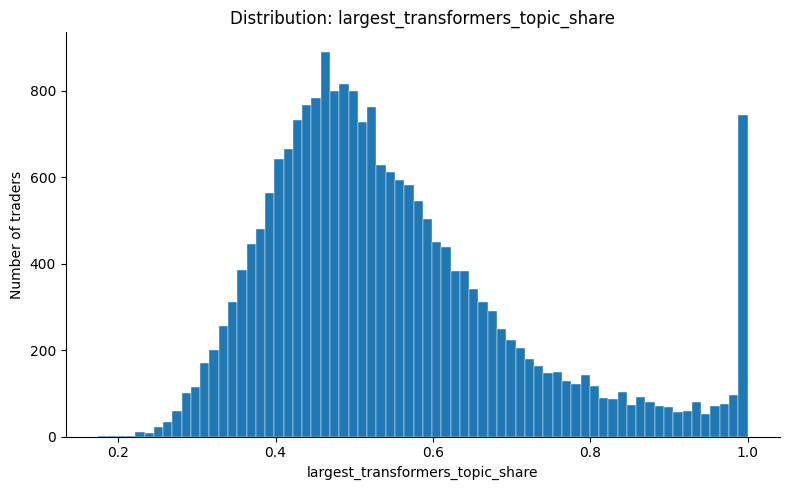

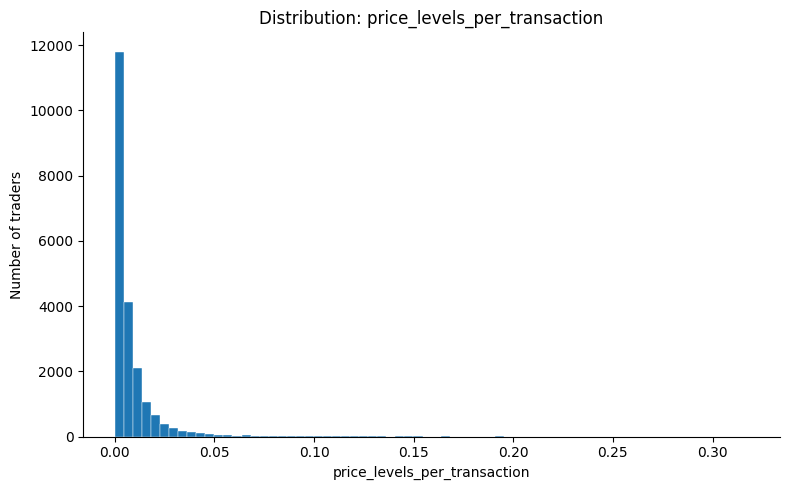

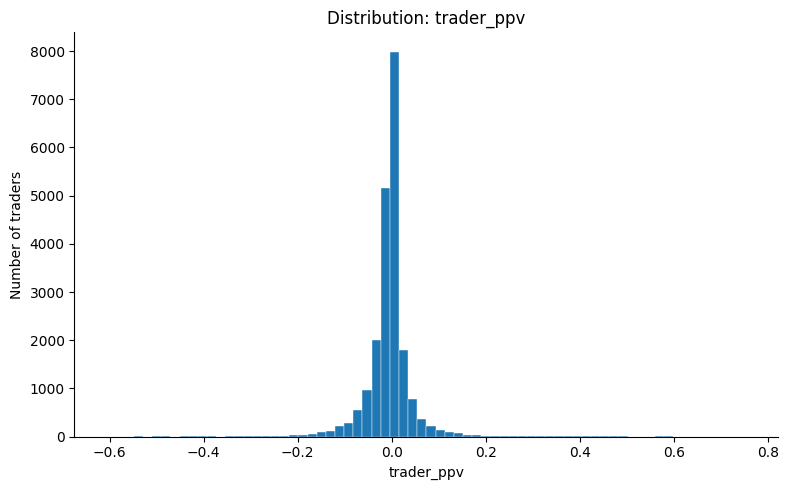

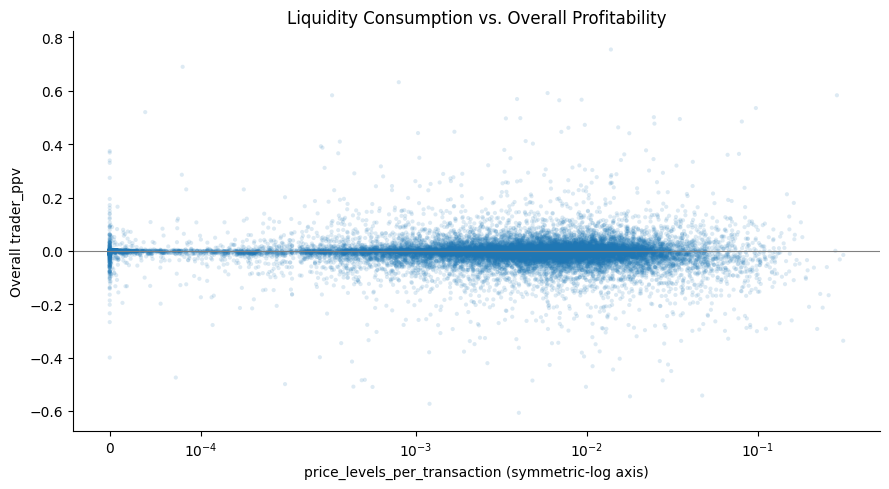

In [3]:
description = primary[[S,L,P]].describe(percentiles=[.01,.1,.25,.5,.75,.9,.99]).T
description['median'] = primary[[S,L,P]].median()
description['skewness'] = primary[[S,L,P]].skew()
display(description)
print('Zero liquidity values:', int(primary[L].eq(0).sum()))
print('Negative liquidity values retained:', int(primary[L].lt(0).sum()))
if 'price_levels_consumed' in working:
    source = pd.to_numeric(working.loc[primary.index,'price_levels_consumed'],errors='raise')
    valid = np.isfinite(source)
    if valid.any():
        implied = source.loc[valid]/primary.loc[valid,'transaction_count']
        print('Proxy matches price_levels_consumed / count:', f'{np.isclose(implied,primary.loc[valid,L],rtol=1e-5,atol=1e-8).mean():.2%}')
for col in [S,L,P]:
    fig, ax = plt.subplots(figsize=(8,5))
    ax.hist(primary[col],bins=70,edgecolor='white',linewidth=.3)
    ax.set(title=f'Distribution: {col}',xlabel=col,ylabel='Number of traders')
    fig.tight_layout(); plt.show(); plt.close(fig)
nonzero = primary.loc[primary[L].ne(0),L].abs()
linthresh = max(float(nonzero.quantile(.1)),1e-8) if len(nonzero) else 1e-8
fig, ax = plt.subplots(figsize=(9,5))
ax.scatter(primary[L],primary[P],s=9,alpha=.15,edgecolors='none',rasterized=True)
ax.set_xscale('symlog',linthresh=linthresh)
ax.axhline(0,color='gray',lw=.8)
ax.set(title='Liquidity Consumption vs. Overall Profitability',xlabel=f'{L} (symmetric-log axis)',ylabel='Overall trader_ppv')
fig.tight_layout(); plt.show(); plt.close(fig)
print('Symmetric-log linear-region threshold:',linthresh)

# 5. Exploratory Correlations
Pearson and Spearman correlations describe linear and rank associations, not moderation. Constant inputs yield missing results. BH correction covers the six exploratory tests; dependent tests warrant caution. Inference assumes independent traders, which shared markets or related wallets may violate.

In [4]:
def corrected(p, method='fdr_bh'):
    values = np.asarray(p,dtype=float)
    out = np.full(len(values),np.nan)
    valid = np.isfinite(values)
    if valid.any():
        out[valid] = multipletests(values[valid],method=method)[1]
    return out
rows = []
for a,b in [(S,P),(L,P),(S,L)]:
    for method,fn in [('Pearson',stats.pearsonr),('Spearman',stats.spearmanr)]:
        r,p = fn(primary[a],primary[b]) if primary[a].nunique()>1 and primary[b].nunique()>1 else (np.nan,np.nan)
        rows.append({'a':a,'b':b,'method':method,'coefficient':r,'p_value':p,'n':len(primary)})
correlations = pd.DataFrame(rows)
correlations['q_bh'] = corrected(correlations.p_value)
display(correlations)

,a,b,method,coefficient,p_value,n,q_bh
0,largest_transformers_topic_share,trader_ppv,Pearson,-0.012247,7.372379e-02,21323,7.372379e-02
1,largest_transformers_topic_share,trader_ppv,Spearman,-0.020297,3.037579e-03,21323,3.645095e-03
2,price_levels_per_transaction,trader_ppv,Pearson,-0.071657,1.107516e-25,21323,3.322549e-25
3,price_levels_per_transaction,trader_ppv,Spearman,-0.072323,3.927054e-26,21323,2.356232e-25
4,largest_transformers_topic_share,price_levels_per_transaction,Pearson,0.023352,6.491202e-04,21323,9.736803e-04
5,largest_transformers_topic_share,price_levels_per_transaction,Spearman,-0.064950,2.229964e-21,21323,4.459929e-21


# 6. Specialization-Group Analysis
Use specialization thirds and five **common full-sample liquidity bins**. Drop duplicate quantile boundaries rather than split identical values by arbitrary ranks. If fewer than three specialization groups exist, use neutral ascending labels. Report boundaries, observed ranges, and actual counts. The first interval includes both endpoints; subsequent intervals exclude the left endpoint. Empty profitability bins remain missing.

Specialization thirds: requested 3, actual 3 groups.
Common liquidity quintiles: requested 5, actual 5 groups.


,group,lower_boundary,upper_boundary,observed_min,observed_max,n
0,Q1,0.174494,0.462201,0.174494,0.462188,7108.0
1,Q2,0.462201,0.581099,0.462228,0.581092,7107.0
2,Q3,0.581099,1.000000,0.581103,1.000000,7108.0


,group,lower_boundary,upper_boundary,observed_min,observed_max,n
0,Q1,0.000000,0.000312,0.000000,0.000311,4265.0
1,Q2,0.000312,0.002314,0.000312,0.002313,4264.0
2,Q3,0.002314,0.005404,0.002314,0.005403,4265.0
3,Q4,0.005404,0.011136,0.005404,0.011132,4264.0
4,Q5,0.011136,0.317981,0.011138,0.317981,4265.0


n  mean_ppv  median_ppv   std_ppv
specialization_group liquidity_bin                                      
Low                  Q1             1214 -0.002743   -0.000007  0.030863
                     Q2             1374 -0.004542   -0.002350  0.044656
                     Q3             1484 -0.006117   -0.003165  0.040325
                     Q4             1559 -0.005173   -0.003146  0.039732
                     Q5             1477 -0.009000   -0.005994  0.055132
Moderate             Q1             1276 -0.004136   -0.000035  0.032217
                     Q2             1542 -0.004481   -0.002662  0.045675
                     Q3             1495 -0.003545   -0.002914  0.039354
                     Q4             1476 -0.004890   -0.004205  0.047085
                     Q5             1318 -0.011423   -0.006400  0.060294
High                 Q1             1775 -0.001799   -0.000042  0.042301
                     Q2             1348 -0.007863   -0.003175  0.072499
                     Q3             1286 -0.005264   -0.003904  0.066057
                     Q4             1229 -0.007786   -0.004880  0.071613
                     Q5             1470 -0.014009   -0.009737  0.089961

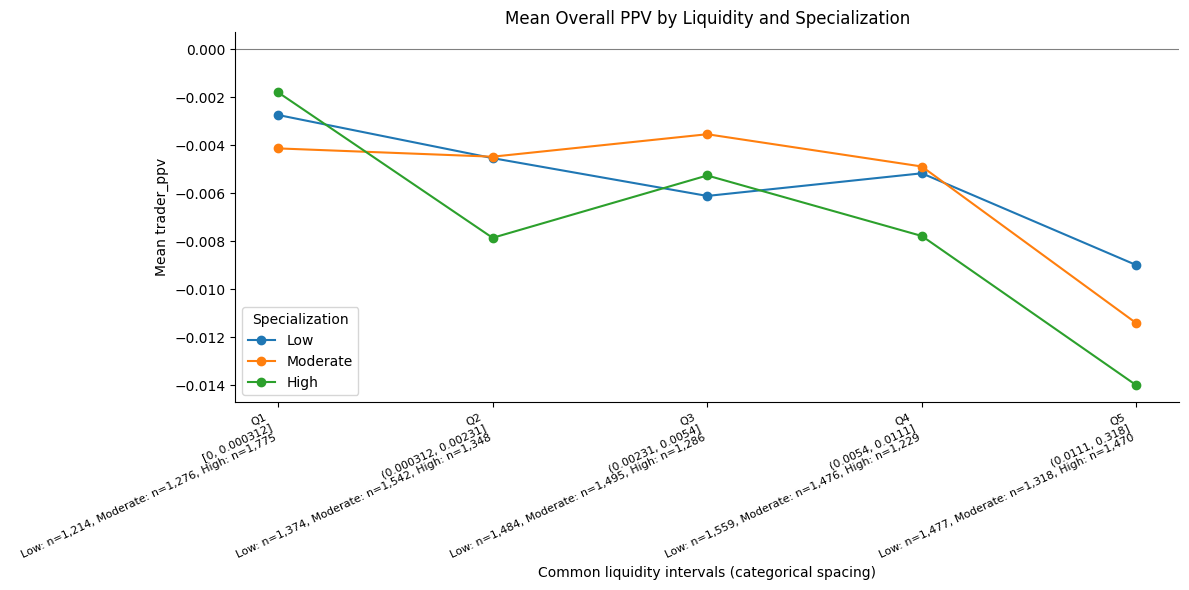

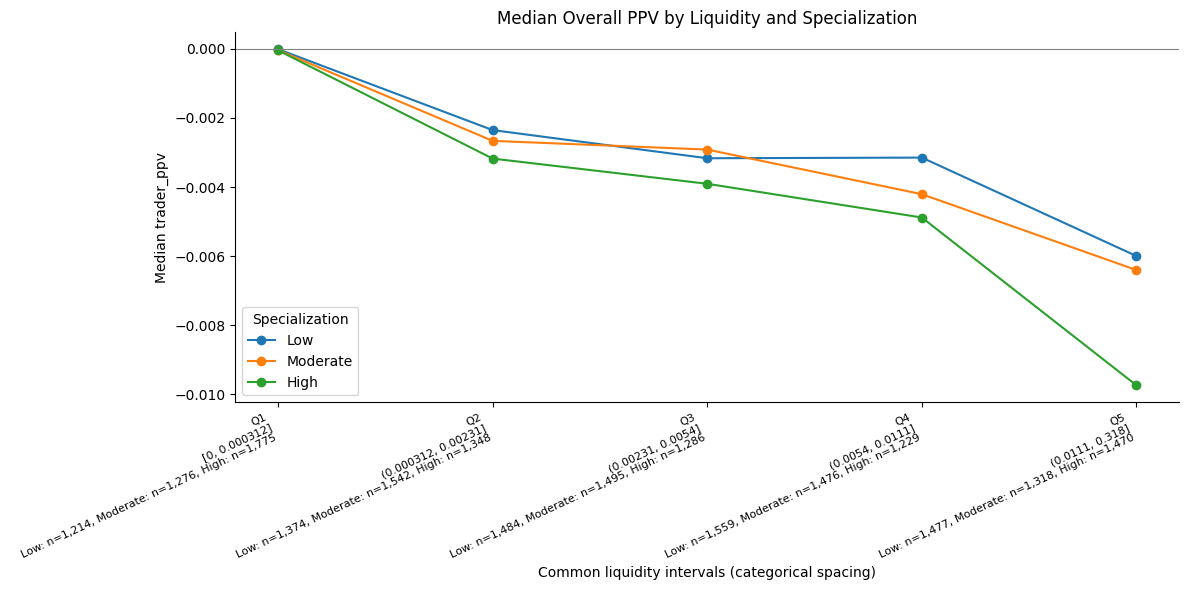

In [5]:
def quantile_bins(series,q,name):
    if series.nunique()==1:
        edges=np.array([series.iloc[0],series.iloc[0]])
        groups=pd.Series(pd.Categorical(['Q1']*len(series),categories=['Q1'],ordered=True),index=series.index)
    else:
        _,edges=pd.qcut(series,q=q,duplicates='drop',retbins=True)
        groups=pd.cut(series,edges,labels=[f'Q{i+1}' for i in range(len(edges)-1)],include_lowest=True)
    observed=pd.DataFrame({'value':series,'group':groups}).groupby('group',observed=False).value.agg(['min','max','size'])
    info=pd.DataFrame({'group':groups.cat.categories,'lower_boundary':edges[:-1],'upper_boundary':edges[1:]})
    info[['observed_min','observed_max','n']]=observed.to_numpy()
    print(f'{name}: requested {q}, actual {len(info)} groups.'+(' Reduced due to tied boundaries/constant values.' if len(info)<q else ''))
    display(info)
    assert groups.notna().all()
    return groups,edges,info

def interval_labels(edges):
    return [f"Q{i+1}\n{'[' if i==0 else '('}{a:.3g}, {b:.3g}]" for i,(a,b) in enumerate(zip(edges[:-1],edges[1:]))]
def summarize(data,keys):
    return data.groupby(keys,observed=False).agg(n=(P,'size'),mean_ppv=(P,'mean'),median_ppv=(P,'median'),std_ppv=(P,'std'))
s3,s3_edges,s3_info=quantile_bins(primary[S],3,'Specialization thirds')
s3=s3.cat.rename_categories(['Low','Moderate','High'] if len(s3.cat.categories)==3 else [f'Group {i+1} (ascending)' for i in range(len(s3.cat.categories))])
l5,l5_edges,l5_info=quantile_bins(primary[L],5,'Common liquidity quintiles')
primary['specialization_group'],primary['liquidity_bin']=s3,l5
group_summary=summarize(primary,['specialization_group','liquidity_bin'])
display(group_summary)
assert group_summary.n.sum()==len(primary)
l_labels=interval_labels(l5_edges)
for statistic,title in [('mean_ppv','Mean'),('median_ppv','Median')]:
    fig,ax=plt.subplots(figsize=(12,6))
    for group in s3.cat.categories:
        table=group_summary.loc[group]
        ax.plot(range(len(table)),table[statistic],marker='o',label=group)
    counts=group_summary.n.unstack('specialization_group')
    ticks=[label+'\n'+', '.join(f'{g}: n={int(counts.loc[q,g]):,}' for g in s3.cat.categories) for q,label in zip(l5.cat.categories,l_labels)]
    ax.set_xticks(range(len(ticks)),ticks,rotation=25,ha='right',fontsize=8)
    ax.axhline(0,color='gray',lw=.8)
    ax.set(title=f'{title} Overall PPV by Liquidity and Specialization',xlabel='Common liquidity intervals (categorical spacing)',ylabel=f'{title} trader_ppv')
    ax.legend(title='Specialization')
    fig.tight_layout(); plt.show(); plt.close(fig)

# 7. Profitability Heatmaps
Independently defined quintiles use common boundaries across all traders. Means and medians share a zero-centered scale. `NA` indicates no observations and differs from measured zero. Counts reveal sparse cells; extreme cell averages may be unstable.

Specialization quintiles: requested 5, actual 5 groups.


,group,lower_boundary,upper_boundary,observed_min,observed_max,n
0,Q1,0.174494,0.418680,0.174494,0.418663,4265.0
1,Q2,0.418680,0.482235,0.418706,0.482224,4264.0
2,Q3,0.482235,0.552048,0.482238,0.552047,4265.0
3,Q4,0.552048,0.660530,0.552051,0.660522,4264.0
4,Q5,0.660530,1.000000,0.660535,1.000000,4265.0


n  mean_ppv  median_ppv   std_ppv
liquidity_bin specialization_quintile                                      
Q1            Q1                        751 -0.002351   -0.000003  0.027354
              Q2                        678 -0.003288   -0.000021  0.032793
              Q3                        753 -0.004795   -0.000037  0.036663
              Q4                       1014 -0.003473   -0.000633  0.020742
              Q5                       1069 -0.000630   -0.000006  0.052222
Q2            Q1                        784 -0.005289   -0.002673  0.046780
              Q2                        939 -0.003918   -0.002429  0.042285
              Q3                        877 -0.002957   -0.001769  0.048442
              Q4                        858 -0.006960   -0.003313  0.045366
              Q5                        806 -0.009130   -0.003091  0.084974
Q3            Q1                        889 -0.004981   -0.002780  0.043781
              Q2                        889 -0.006917   -0.003472  0.035820
              Q3                        918 -0.003367   -0.002731  0.038960
              Q4                        799 -0.004549   -0.004012  0.045533
              Q5                        770 -0.004992   -0.003746  0.076018
Q4            Q1                        942 -0.004814   -0.002383  0.042298
              Q2                        898 -0.005171   -0.003835  0.038871
              Q3                        950 -0.005425   -0.004228  0.043703
              Q4                        773 -0.005669   -0.004150  0.051976
              Q5                        701 -0.008754   -0.005748  0.085269
Q5            Q1                        899 -0.011083   -0.006891  0.056879
              Q2                        860 -0.008047   -0.005600  0.052405
              Q3                        767 -0.009262   -0.004944  0.062433
              Q4                        820 -0.013097   -0.009622  0.060619
              Q5                        919 -0.015468   -0.010368  0.103799

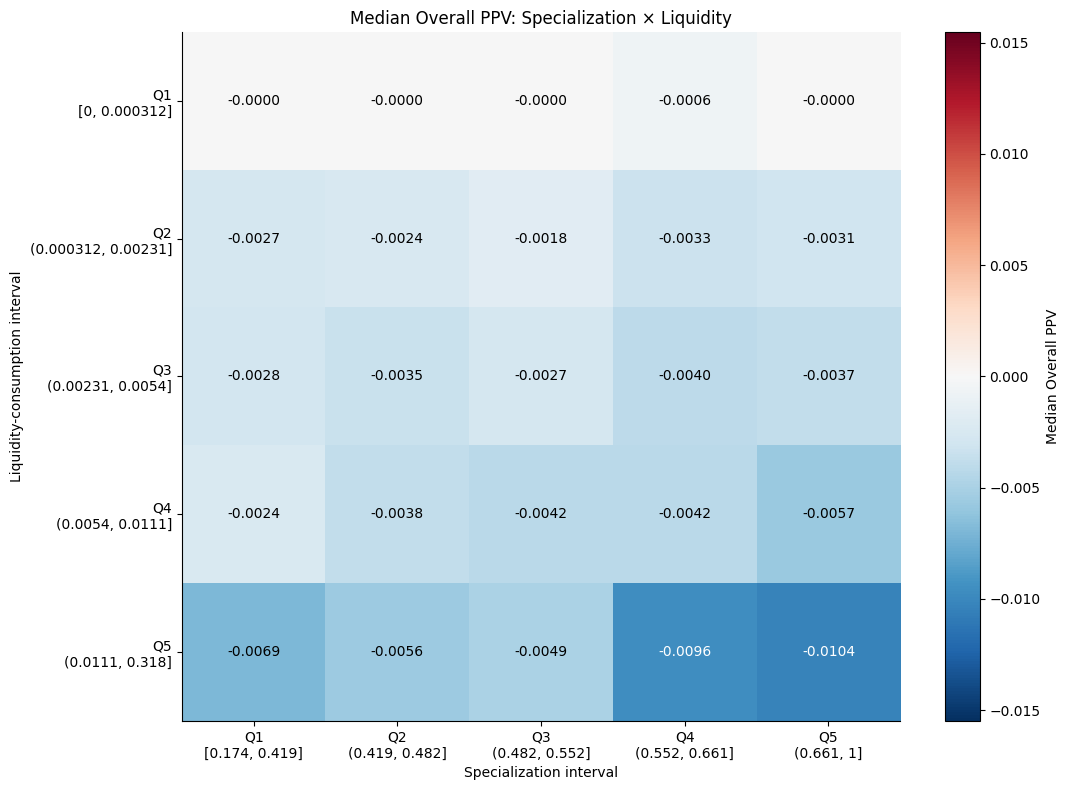

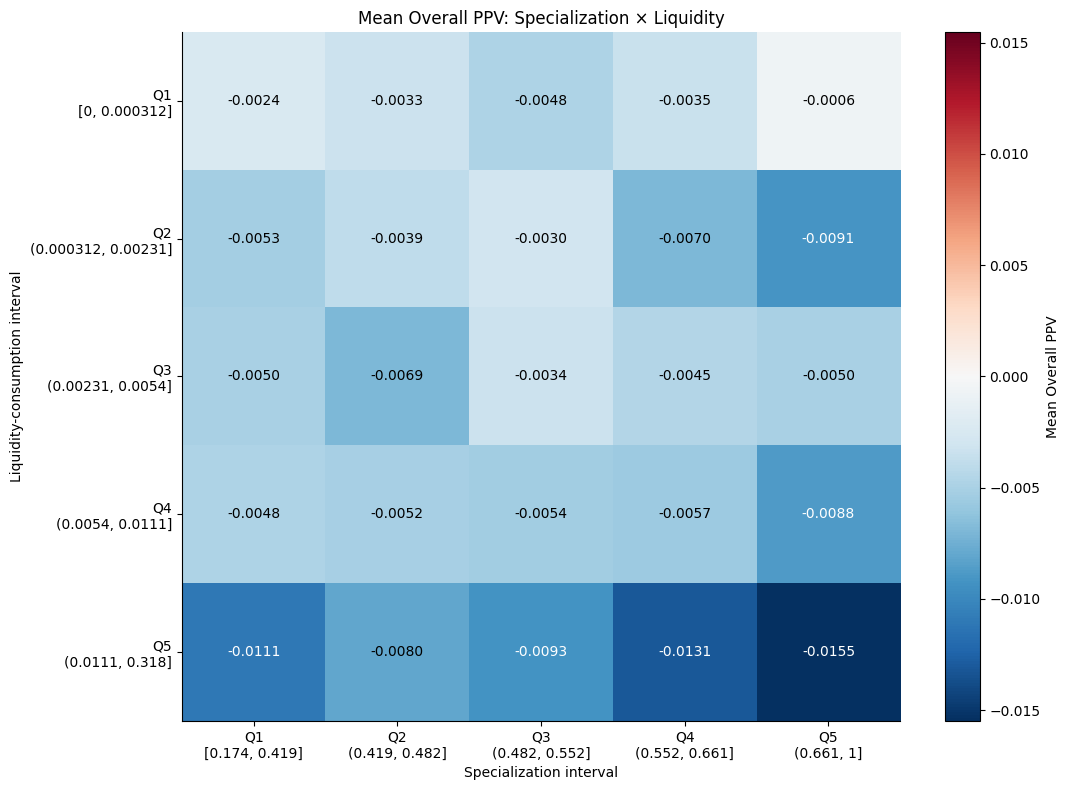

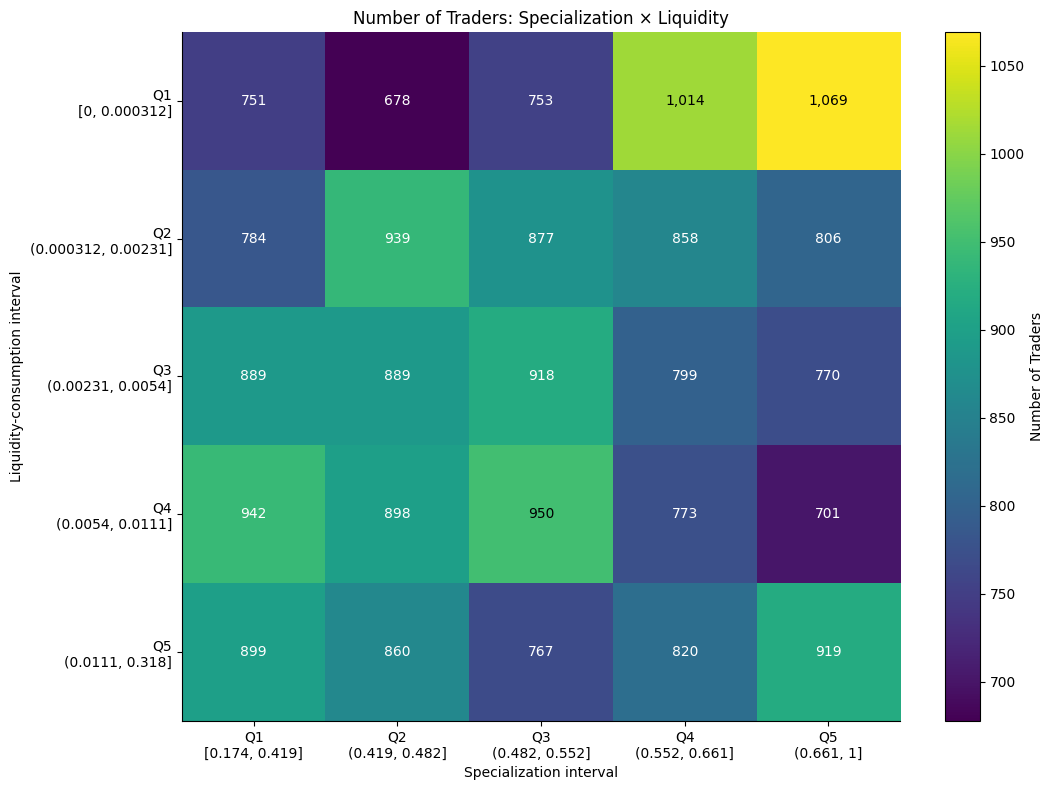

In [6]:
s5,s5_edges,s5_info=quantile_bins(primary[S],5,'Specialization quintiles')
primary['specialization_quintile']=s5
heat_summary=summarize(primary,['liquidity_bin','specialization_quintile'])
display(heat_summary)
assert heat_summary.n.sum()==len(primary)
limit=max(float(heat_summary[['mean_ppv','median_ppv']].abs().max().max()),1e-12)
for statistic,title in [('median_ppv','Median Overall PPV'),('mean_ppv','Mean Overall PPV'),('n','Number of Traders')]:
    values=heat_summary[statistic].unstack('specialization_quintile').to_numpy(dtype=float)
    fig,ax=plt.subplots(figsize=(11,8))
    cmap=plt.get_cmap('viridis' if statistic=='n' else 'RdBu_r').copy()
    cmap.set_bad('#dddddd')
    opts={} if statistic=='n' else {'norm':TwoSlopeNorm(vmin=-limit,vcenter=0,vmax=limit)}
    im=ax.imshow(np.ma.masked_invalid(values),cmap=cmap,aspect='auto',**opts)
    ax.set_xticks(range(len(s5.cat.categories)),interval_labels(s5_edges))
    ax.set_yticks(range(len(l5.cat.categories)),l_labels)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            v=values[i,j]
            label='NA' if np.isnan(v) else (f'{v:,.0f}' if statistic=='n' else f'{v:.4f}')
            rgba=im.cmap(im.norm(v)) if np.isfinite(v) else (1,1,1,1)
            color='black' if np.dot(rgba[:3],[.299,.587,.114])>.55 else 'white'
            ax.text(j,i,label,ha='center',va='center',color=color)
    ax.set(title=f'{title}: Specialization × Liquidity',xlabel='Specialization interval',ylabel='Liquidity-consumption interval')
    fig.colorbar(im,ax=ax,label=title)
    fig.tight_layout(); plt.show(); plt.close(fig)

# 8. Primary Interaction Regression
Formula `L * S` includes both main effects and their interaction once. Keep the raw proxy units in the primary model. HC3 standard errors allow heteroskedasticity but do not make OLS resistant to outliers or account for dependence across traders. Two-sided normal-reference tests are primary. The directional test uses the signed z statistic; it is not half the two-sided p-value for a negative coefficient.

The prediction grid is the intersection of local 5th–95th percentile liquidity ranges among traders within ±0.05 specialization units of each selected percentile. Require at least 100 traders per local window. These diagnostics reduce extrapolation but cannot establish dense support at every combination. All observations remain in estimation. Bands are pointwise confidence intervals for fitted means, not individual prediction intervals.

Prespecified positive-direction one-sided p: 0.42639827324950996
Common local-support prediction range: [1.27193e-05, 0.0260398]


,coefficient,HC3_SE,ci95_low,ci95_high,p_two_sided,n,R_squared
Intercept,-0.001712,0.002406,-0.006428,0.003004,0.476804,21323,0.005272
price_levels_per_transaction,-0.308002,0.259001,-0.815635,0.199631,0.234364,21323,0.005272
largest_transformers_topic_share,-0.004243,0.004647,-0.013350,0.004865,0.361219,21323,0.005272
price_levels_per_transaction:largest_transformers_topic_share,0.090713,0.488882,-0.867479,1.048905,0.852797,21323,0.005272


,specialization_percentile,specialization_value,slope_per_proxy_unit,HC3_SE,ci95_low,ci95_high,n_model
0,0.1,0.375259,-0.273961,0.083510,-0.437642,-0.110281,21323
1,0.5,0.514616,-0.261320,0.042341,-0.344308,-0.178332,21323
2,0.9,0.789830,-0.236355,0.137222,-0.505310,0.032601,21323


,percentile,S,local_n,L_q05,L_q95
0,0.1,0.375259,3967,0.000000,0.028122
1,0.5,0.514616,6117,0.000000,0.026040
2,0.9,0.789830,1034,0.000013,0.040959


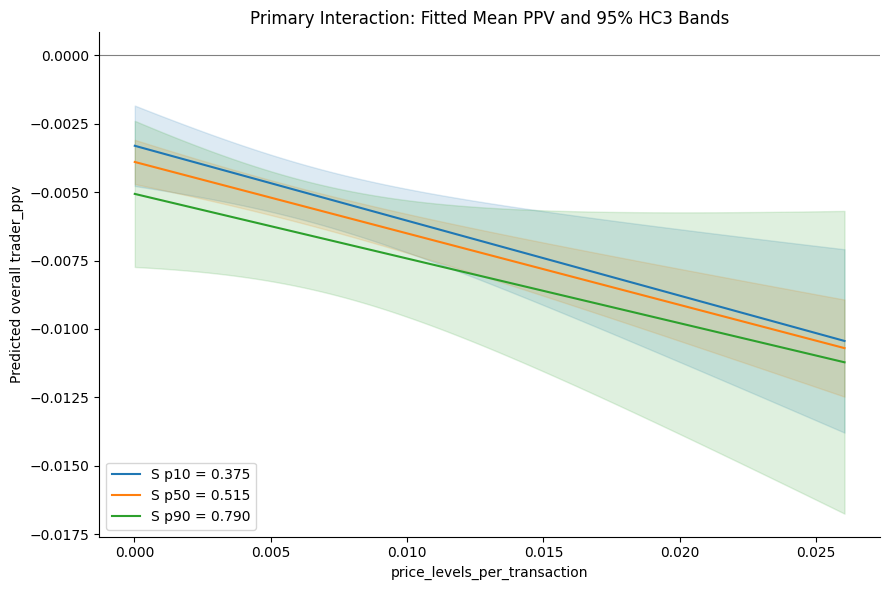

In [7]:
def fit_interaction(data,outcome=P,specialization=S,execution=L,extra=None):
    formula=f'{outcome} ~ {execution} * {specialization}'
    if extra:
        formula+=' + '+' + '.join(extra)
    model=smf.ols(formula,data=data,missing='raise').fit(cov_type='HC3',use_t=False)
    if np.linalg.matrix_rank(model.model.exog)<model.model.exog.shape[1]:
        raise ValueError('Rank-deficient regression design; effects not identified.')
    return model

def coefficient_table(model):
    ci=model.conf_int()
    return pd.DataFrame({'coefficient':model.params,'HC3_SE':model.bse,'ci95_low':ci[0],'ci95_high':ci[1],
                         'p_two_sided':model.pvalues,'n':int(model.nobs),'R_squared':model.rsquared})

def interaction_record(label,model,specialization=S,execution=L,outcome=P):
    term=f'{execution}:{specialization}'
    ci=model.conf_int().loc[term]
    return {'analysis':label,'outcome':outcome,'n':int(model.nobs),'interaction':model.params[term],
            'ci95_low':ci.iloc[0],'ci95_high':ci.iloc[1],'p_two_sided':model.pvalues[term],'R_squared':model.rsquared}

primary_model=fit_interaction(primary)
display(coefficient_table(primary_model))
interaction_term=f'{L}:{S}'
primary_record=interaction_record('Primary, threshold 100',primary_model)
primary_z=primary_model.params[interaction_term]/primary_model.bse[interaction_term]
print('Prespecified positive-direction one-sided p:',float(stats.norm.sf(primary_z)))
specialization_levels=primary[S].quantile([.1,.5,.9])
slope_rows=[]
for percentile,level in specialization_levels.items():
    contrast=pd.Series(0.0,index=primary_model.params.index)
    contrast[L],contrast[interaction_term]=1,level
    slope=float(contrast @ primary_model.params)
    se=float(np.sqrt(contrast @ primary_model.cov_params() @ contrast))
    slope_rows.append({'specialization_percentile':percentile,'specialization_value':level,'slope_per_proxy_unit':slope,
                       'HC3_SE':se,'ci95_low':slope-1.96*se,'ci95_high':slope+1.96*se,'n_model':len(primary)})
conditional_slopes=pd.DataFrame(slope_rows)
display(conditional_slopes)
support_rows=[]
for percentile,level in specialization_levels.items():
    local=primary.loc[(primary[S]-level).abs()<=.05]
    support_rows.append({'percentile':percentile,'S':level,'local_n':len(local),'L_q05':local[L].quantile(.05),'L_q95':local[L].quantile(.95)})
support=pd.DataFrame(support_rows)
display(support)
lo,hi=support.L_q05.max(),support.L_q95.min()
if (support.local_n>=100).all() and np.isfinite([lo,hi]).all() and hi>lo:
    print(f'Common local-support prediction range: [{lo:.6g}, {hi:.6g}]')
    fig,ax=plt.subplots(figsize=(9,6))
    for percentile,level in specialization_levels.items():
        grid=pd.DataFrame({L:np.linspace(lo,hi,150),S:level})
        design_frame=pd.DataFrame({'Intercept':1.0,L:grid[L],S:grid[S],interaction_term:grid[L]*grid[S]})
        design=design_frame[primary_model.params.index].to_numpy()
        fitted=design @ primary_model.params.to_numpy()
        se=np.sqrt(np.maximum(np.einsum('ij,jk,ik->i',design,primary_model.cov_params().to_numpy(),design),0))
        line,=ax.plot(grid[L],fitted,label=f'S p{int(percentile*100)} = {level:.3f}')
        ax.fill_between(grid[L],fitted-1.96*se,fitted+1.96*se,color=line.get_color(),alpha=.15)
    ax.axhline(0,color='gray',lw=.8)
    ax.set(title='Primary Interaction: Fitted Mean PPV and 95% HC3 Bands',xlabel=L,ylabel='Predicted overall trader_ppv')
    ax.legend()
    fig.tight_layout(); plt.show(); plt.close(fig)
else:
    print('Prediction plot skipped: insufficient overlapping local support.')

# 9. Controlled Regression
Add transaction size, frequency, and markets per day, centered after `log1p` to reduce skew. Unexpected negative controls use signed `log1p(abs(x))` with a warning, retaining finite records. Control coefficients are per transformed unit, conditional on other regressors. Raw liquidity and specialization units stay unchanged. Outcomes are not logged.

Compare the controlled model with an unadjusted model on the **same complete-case sample**, separating adjustment from sample changes. Inspect correlations and VIFs. For VIF diagnostics, standardize and center main predictors before forming the interaction to reduce algebraic collinearity. This preserves the regression span; it does not remove substantive collinearity. VIF > 10 is a diagnostic flag, not an automatic deletion rule.

A separate volume-adjusted sensitivity model is reported. Volume may be the PPV denominator and share construction with other controls. Adjustment does not automatically resolve metric construction or eliminate all confounding.

In [8]:
def transformed_controls(data,columns):
    result=data.copy()
    names=[]
    for col in columns:
        x=result[col]
        if x.lt(0).any():
            print(f'WARNING: negative {col}; signed log1p used, no exclusions.')
        z=np.sign(x)*np.log1p(np.abs(x))
        name='log_'+col+'_c'
        result[name]=z-z.mean()
        names.append(name)
        print(f'{col}: raw skew={x.skew():.3g}, transformed skew={z.skew():.3g}')
    return result,names

def vif_diagnostics(data,names):
    base=data[[L,S]+names]
    scale=base.std(ddof=0)
    if (scale==0).any():
        print('Constant predictors:',scale.index[scale==0].tolist())
        return
    z=(base-base.mean())/scale
    z['centered_interaction']=z[L]*z[S]
    design=sm.add_constant(z)
    table=pd.DataFrame({'term':design.columns[1:],'VIF':[variance_inflation_factor(design.to_numpy(),i) for i in range(1,design.shape[1])]})
    display(table)
    print('VIF > 10 flags:',table.loc[table.VIF>10,'term'].tolist())

controlled=sample_for([S,L,P]+controls,label='Controlled PPV')
controlled,control_names=transformed_controls(controlled,controls)
matched_model=fit_interaction(controlled)
controlled_model=fit_interaction(controlled,extra=control_names)
print('Controlled model:')
display(coefficient_table(controlled_model))
print('Unadjusted model on identical sample:')
display(coefficient_table(matched_model))
comparison=pd.DataFrame([primary_record,interaction_record('Unadjusted, control-complete',matched_model),interaction_record('Controlled',controlled_model)])
display(comparison)
print('Transformed predictor Pearson correlations:')
display(controlled[[L,S]+control_names].corr())
print('Raw predictor Spearman correlations:')
display(controlled[[L,S]+controls].corr(method='spearman'))
vif_diagnostics(controlled,control_names)
volume_sample=sample_for([S,L,P,'trader_volume']+controls,label='Volume-adjusted PPV sensitivity')
volume_sample,volume_names=transformed_controls(volume_sample,controls+['trader_volume'])
volume_model=fit_interaction(volume_sample,extra=volume_names)
display(coefficient_table(volume_model))
display(volume_sample[[L,S]+volume_names].corr())
vif_diagnostics(volume_sample,volume_names)
pnl=working.loc[volume_sample.index,'trader_pnl']
valid=volume_sample.trader_volume.gt(0)&np.isfinite(pnl)
if valid.any():
    ratio=pnl.loc[valid]/volume_sample.loc[valid,'trader_volume']
    print(f'PPV numerically matches PNL/volume (n={valid.sum():,}): {np.isclose(volume_sample.loc[valid,P],ratio,rtol=1e-5,atol=1e-8).mean():.2%}')

mean_tx_value: raw skew=9.59, transformed skew=-0.167
transactions_per_day: raw skew=24.8, transformed skew=1
markets_per_day: raw skew=5.29, transformed skew=0.911
Controlled model:
Unadjusted model on identical sample:
Transformed predictor Pearson correlations:
Raw predictor Spearman correlations:
VIF > 10 flags: []
mean_tx_value: raw skew=9.59, transformed skew=-0.167
transactions_per_day: raw skew=24.8, transformed skew=1
markets_per_day: raw skew=5.29, transformed skew=0.911
trader_volume: raw skew=22.4, transformed skew=0.0863
VIF > 10 flags: []
PPV numerically matches PNL/volume (n=21,323): 100.00%


,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Controlled PPV,100,524760,21323,0,21323


,coefficient,HC3_SE,ci95_low,ci95_high,p_two_sided,n,R_squared
Intercept,0.001749,0.002423,-0.003000,0.006499,4.703873e-01,21323,0.008436
price_levels_per_transaction,-0.377105,0.258738,-0.884223,0.130012,1.449840e-01,21323,0.008436
largest_transformers_topic_share,-0.009895,0.004683,-0.019073,-0.000716,3.460423e-02,21323,0.008436
price_levels_per_transaction:largest_transformers_topic_share,0.136423,0.489173,-0.822338,1.095185,7.803325e-01,21323,0.008436
log_mean_tx_value_c,0.001081,0.000325,0.000445,0.001717,8.646175e-04,21323,0.008436
log_transactions_per_day_c,0.000741,0.000410,-0.000062,0.001544,7.069519e-02,21323,0.008436
log_markets_per_day_c,-0.004247,0.000763,-0.005741,-0.002752,2.564998e-08,21323,0.008436


,coefficient,HC3_SE,ci95_low,ci95_high,p_two_sided,n,R_squared
Intercept,-0.001712,0.002406,-0.006428,0.003004,0.476804,21323,0.005272
price_levels_per_transaction,-0.308002,0.259001,-0.815635,0.199631,0.234364,21323,0.005272
largest_transformers_topic_share,-0.004243,0.004647,-0.013350,0.004865,0.361219,21323,0.005272
price_levels_per_transaction:largest_transformers_topic_share,0.090713,0.488882,-0.867479,1.048905,0.852797,21323,0.005272


,analysis,outcome,n,interaction,ci95_low,ci95_high,p_two_sided,R_squared
0,"Primary, threshold 100",trader_ppv,21323,0.090713,-0.867479,1.048905,0.852797,0.005272
1,"Unadjusted, control-complete",trader_ppv,21323,0.090713,-0.867479,1.048905,0.852797,0.005272
2,Controlled,trader_ppv,21323,0.136423,-0.822338,1.095185,0.780332,0.008436


,price_levels_per_transaction,largest_transformers_topic_share,log_mean_tx_value_c,log_transactions_per_day_c,log_markets_per_day_c
price_levels_per_transaction,1.000000,0.023352,0.265457,-0.029205,-0.108717
largest_transformers_topic_share,0.023352,1.000000,0.106729,0.110037,-0.283002
log_mean_tx_value_c,0.265457,0.106729,1.000000,0.259287,-0.341954
log_transactions_per_day_c,-0.029205,0.110037,0.259287,1.000000,0.226815
log_markets_per_day_c,-0.108717,-0.283002,-0.341954,0.226815,1.000000


... (2 outputs left out)

,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Volume-adjusted PPV sensitivity,100,524760,21323,0,21323


,coefficient,HC3_SE,ci95_low,ci95_high,p_two_sided,n,R_squared
Intercept,0.001047,0.002435,-0.003726,0.005819,6.673124e-01,21323,0.009038
price_levels_per_transaction,-0.392220,0.258847,-0.899550,0.115110,1.297060e-01,21323,0.009038
largest_transformers_topic_share,-0.008505,0.004702,-0.017722,0.000711,7.049147e-02,21323,0.009038
price_levels_per_transaction:largest_transformers_topic_share,0.149805,0.489363,-0.809329,1.108938,7.595120e-01,21323,0.009038
log_mean_tx_value_c,-0.000244,0.000455,-0.001135,0.000647,5.911807e-01,21323,0.009038
log_transactions_per_day_c,0.000250,0.000421,-0.000576,0.001076,5.530894e-01,21323,0.009038
log_markets_per_day_c,-0.004167,0.000761,-0.005659,-0.002675,4.387537e-08,21323,0.009038
log_trader_volume_c,0.001209,0.000248,0.000723,0.001695,1.079941e-06,21323,0.009038


,price_levels_per_transaction,largest_transformers_topic_share,log_mean_tx_value_c,log_transactions_per_day_c,log_markets_per_day_c,log_trader_volume_c
price_levels_per_transaction,1.000000,0.023352,0.265457,-0.029205,-0.108717,0.242082
largest_transformers_topic_share,0.023352,1.000000,0.106729,0.110037,-0.283002,0.012280
log_mean_tx_value_c,0.265457,0.106729,1.000000,0.259287,-0.341954,0.832941
log_transactions_per_day_c,-0.029205,0.110037,0.259287,1.000000,0.226815,0.373299
log_markets_per_day_c,-0.108717,-0.283002,-0.341954,0.226815,1.000000,-0.217342
log_trader_volume_c,0.242082,0.012280,0.832941,0.373299,-0.217342,1.000000


,term,VIF
0,price_levels_per_transaction,1.192031
1,largest_transformers_topic_share,1.166609
2,log_mean_tx_value_c,3.659730
3,log_transactions_per_day_c,1.413848
4,log_markets_per_day_c,1.431566
5,log_trader_volume_c,3.712963
6,centered_interaction,1.092542


# 10. Transaction-Size Robustness Check
Use full-sample size quintiles and the **same specialization-third and liquidity boundaries** used earlier. Compare the lowest and highest specialization groups within each size stratum. Tables report all cells. Summary lines omit cells with fewer than 30 traders to avoid emphasizing unstable summaries; this is a display rule, not an outlier exclusion.

Report HC3 liquidity slopes for low/high subgroups with at least 100 traders and liquidity variation. Additionally fit continuous-specialization interactions within each size quintile using all its traders, with BH correction across these five exploratory tests. Report unestimable strata. Separate subgroup significance levels do not establish a difference between groups.

Size quintiles: requested 5, actual 5 groups.
Q1: all-trader n=4,265
Q2: all-trader n=4,264
Q3: all-trader n=4,265
Q4: all-trader n=4,264
Q5: all-trader n=4,265


,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Transaction-size stratification,100,524760,21323,0,21323


,group,lower_boundary,upper_boundary,observed_min,observed_max,n
0,Q1,0.017454,9.722622,0.017454,9.719776,4265.0
1,Q2,9.722622,36.903803,9.726891,36.897722,4264.0
2,Q3,36.903803,68.094873,36.905323,68.094431,4265.0
3,Q4,68.094873,152.554299,68.096640,152.479337,4264.0
4,Q5,152.554299,9624.207540,152.604273,9624.207540,4265.0


n  mean_ppv  median_ppv   std_ppv
specialization_group liquidity_bin                                     
Low                  Q1             352 -0.008925   -0.006361  0.041053
                     Q2             599 -0.009025   -0.006205  0.036027
                     Q3             218 -0.007300   -0.004151  0.029238
                     Q4             112 -0.007018   -0.004919  0.019395
                     Q5              80  0.003298    0.000647  0.041902
Moderate             Q1             525 -0.011229   -0.006897  0.035031
                     Q2             699 -0.008296   -0.004826  0.030163
                     Q3             255 -0.009106   -0.004729  0.022626
                     Q4             112 -0.008667   -0.006244  0.024467
                     Q5              67 -0.004559   -0.003308  0.028845
High                 Q1             646 -0.007128   -0.005727  0.028300
                     Q2             361 -0.007446   -0.004478  0.042784
                     Q3             142 -0.011731   -0.003550  0.040153
                     Q4              55 -0.006936   -0.006787  0.044463
                     Q5              42 -0.006135   -0.000830  0.025946

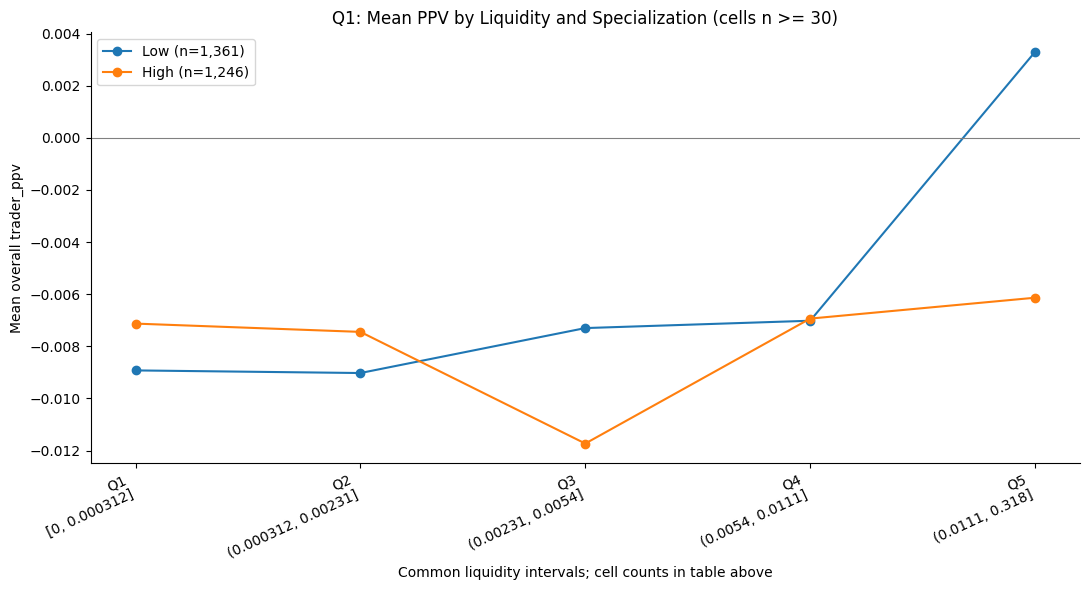

n  mean_ppv  median_ppv   std_ppv
specialization_group liquidity_bin                                     
Low                  Q1              74 -0.003776   -0.002099  0.060002
                     Q2             304 -0.005085   -0.002740  0.040205
                     Q3             447 -0.010555   -0.007145  0.038107
                     Q4             438 -0.005620   -0.004767  0.036729
                     Q5             323 -0.008018   -0.005320  0.045422
Moderate             Q1              76 -0.005441   -0.000161  0.037037
                     Q2             346 -0.007584   -0.002784  0.047042
                     Q3             408 -0.005983   -0.005825  0.036983
                     Q4             382 -0.005665   -0.003763  0.033093
                     Q5             281 -0.009882   -0.005189  0.039948
High                 Q1             182  0.005551   -0.000014  0.069657
                     Q2             280 -0.005885   -0.005548  0.064392
                     Q3             264 -0.002206   -0.004205  0.056397
                     Q4             256 -0.007697   -0.006489  0.046054
                     Q5             203 -0.008769   -0.005553  0.038228

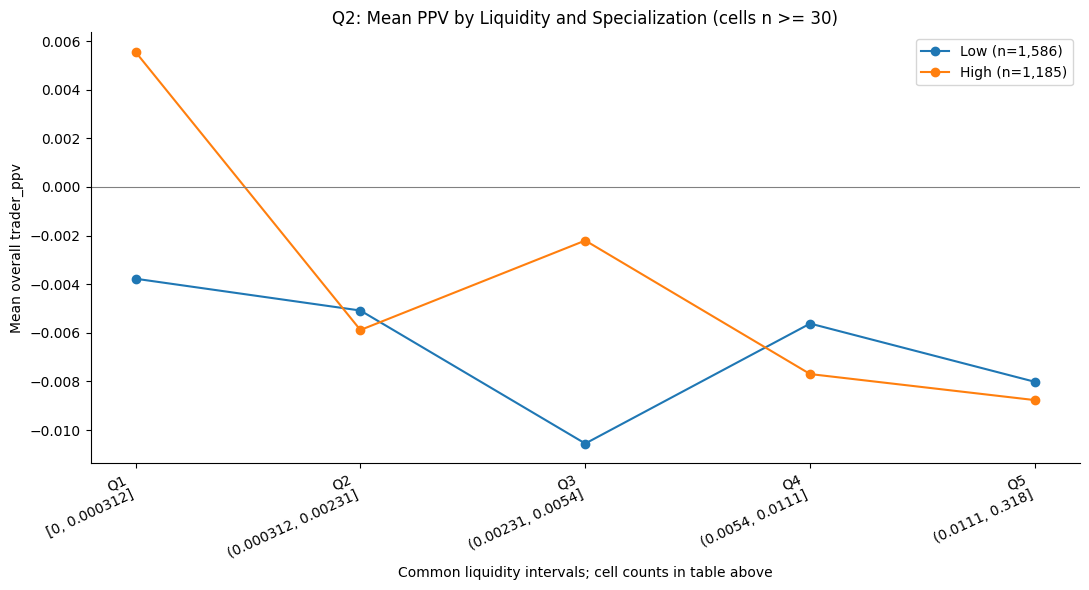

n  mean_ppv    median_ppv   std_ppv
specialization_group liquidity_bin                                       
Low                  Q1             504 -0.000162 -3.101583e-06  0.011184
                     Q2             132  0.001538  1.595898e-03  0.043310
                     Q3             248 -0.002808 -2.972307e-03  0.039847
                     Q4             306 -0.002754 -1.101005e-03  0.037001
                     Q5             264 -0.007644 -5.123269e-03  0.043044
Moderate             Q1             436  0.001678 -1.078591e-05  0.029175
                     Q2             153  0.008201  1.864883e-03  0.051124
                     Q3             244 -0.002377 -4.882744e-03  0.041486
                     Q4             293 -0.008286 -6.281272e-03  0.038247
                     Q5             218 -0.007839 -6.326093e-03  0.053984
High                 Q1             612  0.000338 -7.890676e-07  0.010817
                     Q2             208 -0.006317 -1.065181e-03  0.080826
                     Q3             194 -0.011455 -3.999425e-03  0.044516
                     Q4             233 -0.008458 -4.503722e-03  0.060334
                     Q5             220 -0.018043 -1.440355e-02  0.049797

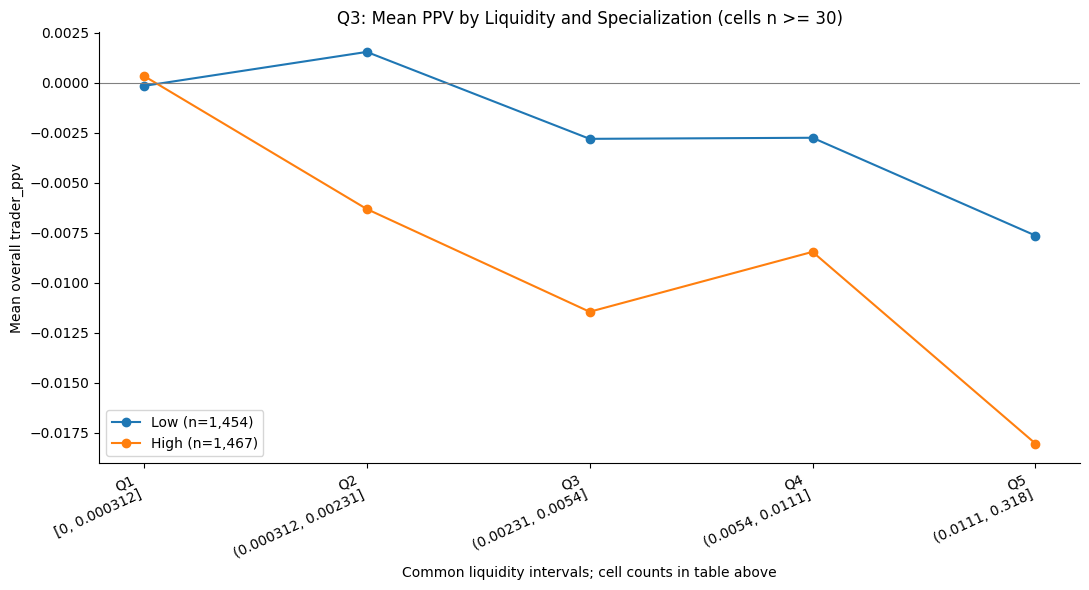

n  mean_ppv    median_ppv   std_ppv
specialization_group liquidity_bin                                       
Low                  Q1             265  0.000731 -2.251375e-06  0.022054
                     Q2             156  0.004040  1.873168e-03  0.054411
                     Q3             293 -0.004406 -1.271554e-03  0.037913
                     Q4             366 -0.005395 -2.475550e-03  0.041875
                     Q5             351 -0.012145 -6.873870e-03  0.051584
Moderate             Q1             218  0.001347 -6.044960e-06  0.016819
                     Q2             163 -0.002922  1.446572e-03  0.050320
                     Q3             308 -0.003099 -1.575685e-03  0.044483
                     Q4             357 -0.004382 -4.075513e-03  0.050351
                     Q5             345 -0.013998 -9.861145e-03  0.049928
High                 Q1             243  0.001576 -1.332044e-18  0.029375
                     Q2             206 -0.014782 -2.606600e-03  0.073982
                     Q3             319 -0.004372 -3.088478e-03  0.060024
                     Q4             304 -0.010228 -4.525137e-03  0.060539
                     Q5             370 -0.014994 -1.056658e-02  0.079914

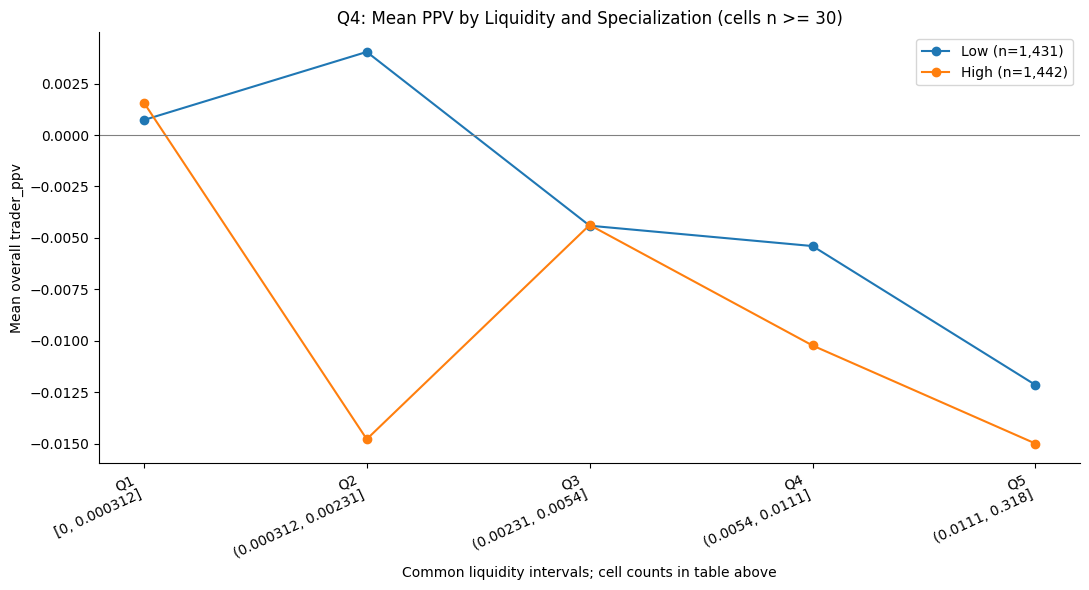

n  mean_ppv  median_ppv   std_ppv
specialization_group liquidity_bin                                     
Low                  Q1              19 -0.001125    0.000831  0.070548
                     Q2             183 -0.000666    0.004014  0.063597
                     Q3             278 -0.002809    0.001872  0.052060
                     Q4             337 -0.005934   -0.001522  0.047816
                     Q5             459 -0.010210   -0.008345  0.070053
Moderate             Q1              21  0.000294    0.002438  0.069825
                     Q2             181  0.004060    0.001691  0.072921
                     Q3             280  0.003561    0.004201  0.045461
                     Q4             332 -0.000275   -0.000407  0.066058
                     Q5             407 -0.013353   -0.004919  0.082833
High                 Q1              92 -0.002055    0.000042  0.126903
                     Q2             293 -0.006501    0.000139  0.097534
                     Q3             367 -0.002465   -0.004865  0.090477
                     Q4             381 -0.005608   -0.003457  0.098560
                     Q5             635 -0.014232   -0.010720  0.116833

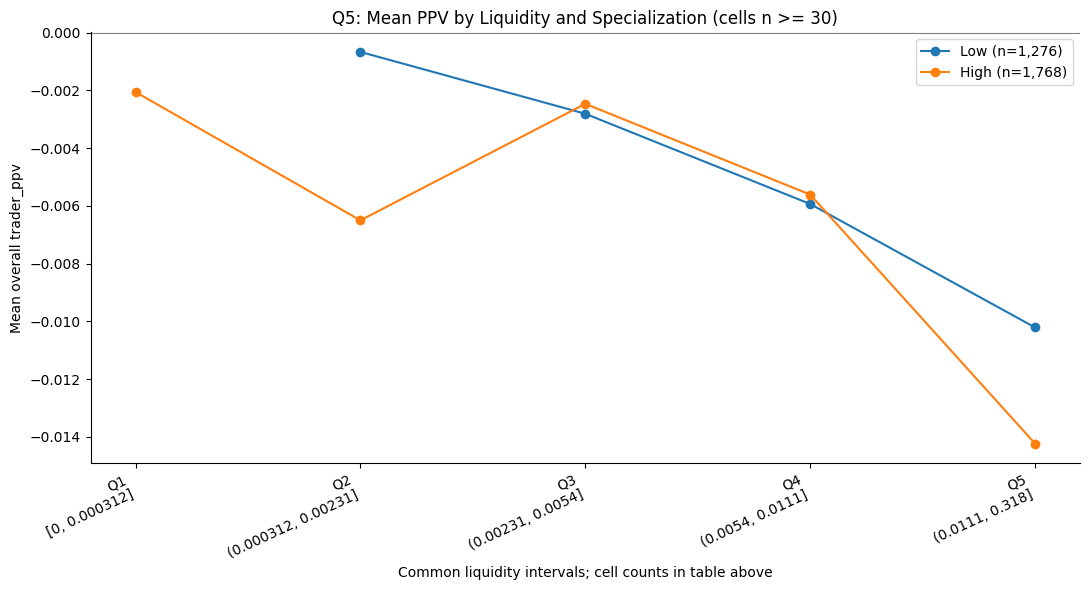

,size_group,specialization_group,n,slope,ci95_low,ci95_high,p
0,Q1,Low,1361,0.874730,0.152066,1.597394,0.017674
1,Q1,High,1246,-0.039138,-0.457497,0.379221,0.854518
2,Q2,Low,1586,0.001573,-0.393414,0.396560,0.993771
3,Q2,High,1185,-0.329170,-0.566467,-0.091872,0.006552
4,Q3,Low,1454,-0.309256,-0.516861,-0.101651,0.003504
5,Q3,High,1467,-0.391774,-0.588926,-0.194622,0.000098
6,Q4,Low,1431,-0.309153,-0.566949,-0.051358,0.018752
7,Q4,High,1442,-0.347401,-0.568152,-0.126649,0.002039
8,Q5,Low,1276,-0.210583,-0.477017,0.055852,0.121357
9,Q5,High,1768,-0.167260,-0.527742,0.193223,0.363139


,analysis,outcome,n,interaction,ci95_low,ci95_high,p_two_sided,R_squared,q_bh
0,Q1,trader_ppv,4265,-2.769949,-4.696814,-0.843084,0.004839,0.006615,0.024197
1,Q2,trader_ppv,4264,-0.783992,-1.694247,0.126263,0.091393,0.002834,0.228483
2,Q3,trader_ppv,4265,-0.088376,-0.749517,0.572765,0.793328,0.013409,0.793328
3,Q4,trader_ppv,4264,-0.224985,-1.169607,0.719638,0.640634,0.013163,0.793328
4,Q5,trader_ppv,4265,0.549746,-1.065318,2.164810,0.504679,0.007454,0.793328


In [9]:
size_sample=sample_for([S,L,P,'mean_tx_value'],label='Transaction-size stratification')
size_groups,size_edges,size_info=quantile_bins(size_sample.mean_tx_value,5,'Size quintiles')
size_sample['size_group']=size_groups
size_sample['specialization_group']=primary.loc[size_sample.index,'specialization_group']
size_sample['liquidity_bin']=primary.loc[size_sample.index,'liquidity_bin']
low_group,high_group=s3.cat.categories[0],s3.cat.categories[-1]
size_records,subgroup_rows=[],[]
for size_group in size_groups.cat.categories:
    subset=size_sample.loc[size_sample.size_group.eq(size_group)]
    print(f'{size_group}: all-trader n={len(subset):,}')
    summary=summarize(subset,['specialization_group','liquidity_bin'])
    display(summary)
    fig,ax=plt.subplots(figsize=(11,6))
    for group in dict.fromkeys([low_group,high_group]):
        selected=subset.loc[subset.specialization_group.eq(group)]
        table=summary.loc[group]
        ax.plot(range(len(table)),table.mean_ppv.where(table.n>=30),marker='o',label=f'{group} (n={len(selected):,})')
        record={'size_group':size_group,'specialization_group':group,'n':len(selected)}
        if len(selected)>=100 and selected[L].nunique()>1:
            model=smf.ols(f'{P} ~ {L}',data=selected).fit(cov_type='HC3',use_t=False)
            ci=model.conf_int().loc[L]
            record.update(slope=model.params[L],ci95_low=ci.iloc[0],ci95_high=ci.iloc[1],p=model.pvalues[L])
        else:
            record['status']='Insufficient sample/variation; not interpreted'
        subgroup_rows.append(record)
    ax.set_xticks(range(len(l_labels)),l_labels,rotation=25,ha='right')
    ax.axhline(0,color='gray',lw=.8)
    ax.set(title=f'{size_group}: Mean PPV by Liquidity and Specialization (cells n >= 30)',xlabel='Common liquidity intervals; cell counts in table above',ylabel='Mean overall trader_ppv')
    ax.legend()
    fig.tight_layout(); plt.show(); plt.close(fig)
    if len(subset)>=100 and subset[S].nunique()>1 and subset[L].nunique()>1:
        try:
            size_records.append(interaction_record(str(size_group),fit_interaction(subset)))
        except ValueError as error:
            print(f'{size_group}: {error}')
    else:
        print(f'{size_group}: insufficient sample/variation for interaction.')
subgroup_slopes=pd.DataFrame(subgroup_rows)
display(subgroup_slopes)
size_interactions=pd.DataFrame(size_records)
if not size_interactions.empty:
    size_interactions['q_bh']=corrected(size_interactions.p_two_sided)
    display(size_interactions)

# 11. Alternative Measures and Robustness Checks
These are exploratory sensitivity analyses, not independent replications. Repeat with tags-based specialization, raw total PNL, and transaction thresholds 50, 100, and 500. Reuse the primary estimate for threshold 100. Also inspect log1p liquidity as a functional-form sensitivity check; its coefficient units differ. Tags specialization is also not strictly commensurate with the primary measure.

PNL depends on trading scale: report both raw PNL and a model with transaction size, frequency, market participation, and volume controls. PPV and PNL are not interchangeable. The file may already exclude incomplete numerical records; changing the threshold **cannot recover observations removed during earlier cleaning**.

No available documentation establishes weighting rules, normalization, or units of `price_levels_consumed_vw`, `price_levels_vw_per_transaction`, or `price_levels_per_volume`. Inspect them but do not fit them as substitute aggression measures. A volume-normalized measure may partly encode inverse transaction size. Numeric reconstruction alone would not establish economic meaning.

Report same-unit coefficient changes explicitly; mark different scales as noncomparable. Exploratory BY correction allows arbitrary dependence among sensitivity tests; the reused primary row is excluded. Confidence intervals are pointwise and not adjusted for multiplicity.

In [10]:
alternative_inspection=sample_for(alt_execution,label='Alternative execution diagnostics only')
display(alternative_inspection[alt_execution].describe().T)
display(pd.DataFrame({'measure':alt_execution,'decision':['Not fitted: unverified weighting/units']*len(alt_execution)}))
robust_records=[dict(primary_record,comparable=True),
                dict(interaction_record('Controlled PPV',controlled_model),comparable=True),
                dict(interaction_record('Volume-adjusted PPV',volume_model),comparable=True)]
tags_sample=sample_for([ALT_S,L,P],label='Tags specialization')
tags_model=fit_interaction(tags_sample,specialization=ALT_S)
robust_records.append(dict(interaction_record('Tags specialization',tags_model,specialization=ALT_S),comparable=False))
pnl_sample=sample_for([S,L,'trader_pnl'],label='Raw PNL outcome')
pnl_model=fit_interaction(pnl_sample,outcome='trader_pnl')
robust_records.append(dict(interaction_record('Raw PNL',pnl_model,outcome='trader_pnl'),comparable=False))
pnl_controlled=sample_for([S,L,'trader_pnl','trader_volume']+controls,label='Scale-adjusted PNL')
pnl_controlled,pnl_names=transformed_controls(pnl_controlled,controls+['trader_volume'])
pnl_controlled_model=fit_interaction(pnl_controlled,outcome='trader_pnl',extra=pnl_names)
robust_records.append(dict(interaction_record('Scale-adjusted PNL',pnl_controlled_model,outcome='trader_pnl'),comparable=False))
for threshold in [50,500]:
    data=sample_for([S,L,P],threshold=threshold,label=f'Threshold {threshold}')
    model=fit_interaction(data)
    robust_records.append(dict(interaction_record(f'Threshold {threshold}',model),comparable=True))
if primary[L].ge(0).all():
    log_liquidity=primary.copy()
    log_liquidity['log_liquidity']=np.log1p(primary[L])
    log_model=fit_interaction(log_liquidity,execution='log_liquidity')
    robust_records.append(dict(interaction_record('log1p liquidity',log_model,execution='log_liquidity'),comparable=False))
else:
    print('log1p liquidity check skipped: negative proxy values require a verified transformation.')
robustness=pd.DataFrame(robust_records)
robustness['direction_vs_primary']=np.where(np.sign(robustness.interaction)==np.sign(primary_record['interaction']),'same','different')
robustness['coefficient_change_same_units']=np.where(robustness.comparable,robustness.interaction-primary_record['interaction'],np.nan)
robustness['magnitude_note']=np.where(robustness.comparable,'Same raw outcome/predictor units','Different outcome or predictor scale; magnitude not directly comparable')
robustness['q_by_exploratory']=np.nan
exploratory=robustness.analysis.ne(primary_record['analysis'])
robustness.loc[exploratory,'q_by_exploratory']=corrected(robustness.loc[exploratory,'p_two_sided'],method='fdr_by')
with pd.option_context('display.max_columns',None):
    display(robustness)
print('Scale-adjusted PNL coefficients:')
display(coefficient_table(pnl_controlled_model))
print('Complete sample audit:')
display(pd.DataFrame(sample_audit))

mean_tx_value: raw skew=9.59, transformed skew=-0.167
transactions_per_day: raw skew=24.8, transformed skew=1
markets_per_day: raw skew=5.29, transformed skew=0.911
trader_volume: raw skew=22.4, transformed skew=0.0863
Scale-adjusted PNL coefficients:
Complete sample audit:


,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Alternative execution diagnostics only,100,524760,21323,0,21323


,count,mean,std,min,25%,50%,75%,max
price_levels_consumed_vw,21323.0,2148.200471,13640.511905,0.0,2.151907,92.340033,722.437999,770520.261458
price_levels_vw_per_transaction,21323.0,2.919888,13.148733,0.0,0.013924,0.375214,1.823110,855.920771
price_levels_per_volume,21323.0,0.007092,0.013391,0.0,0.000611,0.003498,0.008438,0.361355


,measure,decision
0,price_levels_consumed_vw,Not fitted: unverified weighting/units
1,price_levels_vw_per_transaction,Not fitted: unverified weighting/units
2,price_levels_per_volume,Not fitted: unverified weighting/units


,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Tags specialization,100,524760,21323,0,21323


,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Raw PNL outcome,100,524760,21323,0,21323


... (2 outputs left out)

,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Threshold 500,500,524760,4679,0,4679


,analysis,outcome,n,interaction,ci95_low,ci95_high,p_two_sided,R_squared,comparable,direction_vs_primary,coefficient_change_same_units,magnitude_note,q_by_exploratory
0,"Primary, threshold 100",trader_ppv,21323,0.090713,-0.867479,1.048905,0.852797,0.005272,True,same,0.000000,Same raw outcome/predictor units,NaN
1,Controlled PPV,trader_ppv,21323,0.136423,-0.822338,1.095185,0.780332,0.008436,True,same,0.045711,Same raw outcome/predictor units,1.0
2,Volume-adjusted PPV,trader_ppv,21323,0.149805,-0.809329,1.108938,0.759512,0.009038,True,same,0.059092,Same raw outcome/predictor units,1.0
3,Tags specialization,trader_ppv,21323,-0.330940,-1.134657,0.472777,0.419644,0.005618,False,different,NaN,Different outcome or predictor scale; magnitud...,1.0
4,Raw PNL,trader_pnl,21323,-91375.337534,-544589.372742,361838.697674,0.692724,0.001510,False,different,NaN,Different outcome or predictor scale; magnitud...,1.0
5,Scale-adjusted PNL,trader_pnl,21323,-56120.677691,-511703.998078,399462.642696,0.809217,0.015799,False,different,NaN,Different outcome or predictor scale; magnitud...,1.0
6,Threshold 50,trader_ppv,50567,-0.194132,-0.561037,0.172774,0.299723,0.009200,True,different,-0.284844,Same raw outcome/predictor units,1.0
7,Threshold 500,trader_ppv,4679,-1.114022,-2.706239,0.478196,0.170275,0.004481,True,different,-1.204735,Same raw outcome/predictor units,1.0
8,log1p liquidity,trader_ppv,21323,0.064326,-0.893913,1.022564,0.895324,0.005341,False,same,NaN,Different outcome or predictor scale; magnitud...,1.0


,coefficient,HC3_SE,ci95_low,ci95_high,p_two_sided,n,R_squared
Intercept,1208.017118,1247.639959,-1237.312267,3653.346504,3.329236e-01,21323,0.015799
price_levels_per_transaction,-81028.285709,113868.462801,-304206.371775,142149.800357,4.767153e-01,21323,0.015799
largest_transformers_topic_share,768.608840,2382.003073,-3900.031394,5437.249075,7.469427e-01,21323,0.015799
price_levels_per_transaction:largest_transformers_topic_share,-56120.677691,232444.740812,-511703.998078,399462.642696,8.092167e-01,21323,0.015799
log_mean_tx_value_c,-2254.834352,409.541723,-3057.521380,-1452.147324,3.675998e-08,21323,0.015799
log_transactions_per_day_c,-44.331232,304.100182,-640.356635,551.694172,8.840963e-01,21323,0.015799
log_markets_per_day_c,1418.516724,638.230573,167.607788,2669.425660,2.624432e-02,21323,0.015799
log_trader_volume_c,3035.431039,447.501090,2158.345020,3912.517058,1.176489e-11,21323,0.015799


,analysis,threshold,original_n,after_threshold,invalid_removed,final_n
0,Primary PPV,100,524760,21323,0,21323
1,Controlled PPV,100,524760,21323,0,21323
2,Volume-adjusted PPV sensitivity,100,524760,21323,0,21323
3,Transaction-size stratification,100,524760,21323,0,21323
4,Alternative execution diagnostics only,100,524760,21323,0,21323
5,Tags specialization,100,524760,21323,0,21323
6,Raw PNL outcome,100,524760,21323,0,21323
7,Scale-adjusted PNL,100,524760,21323,0,21323
8,Threshold 50,50,524760,50567,0,50567
9,Threshold 500,500,524760,4679,0,4679


# 12. Topic-Specific Analysis (if feasible)
Optional topic regressions are not estimated without a verified common activity-share definition for the topic columns. A largest recorded value does not establish a primary activity topic. Diagnostics below identify actual columns, ties, and all-zero exposure rows without arbitrary assignments.

A future topic analysis would require adequate sample size/variation, multiple-testing correction, and a formal cross-topic interaction-difference test. Comparing coefficients or p-values from separate topic regressions would not establish statistically significant differences. Overall trader profitability would still not be topic-specific trade profit.

In [11]:
topic_columns=[c for c in working.columns if c.startswith('topic_')]
print('Available topic columns:',topic_columns)
if topic_columns:
    topics=working.loc[primary.index,topic_columns].apply(pd.to_numeric,errors='raise')
    valid=np.isfinite(topics.to_numpy(dtype=float,na_value=np.nan)).all(axis=1)
    topics=topics.loc[valid]
    print(f'Finite topic diagnostics available for {len(topics):,} primary-sample traders.')
    if len(topics):
        maxima=topics.max(axis=1)
        ties=np.isclose(topics.to_numpy(),maxima.to_numpy()[:,None],atol=1e-12,rtol=0).sum(axis=1)>1
        print('Tied largest values:',int(ties.sum()))
        print('All-zero topic rows:',int(topics.eq(0).all(axis=1).sum()))
        display(topics.sum(axis=1).describe().rename('Row sum of topic values'))
print('Topic regressions not fitted: primary activity-topic interpretation unverified.')

Available topic columns: ['topic_arts_culture_entertainment_and_media', 'topic_conflict_war_and_peace', 'topic_crime_law_and_justice', 'topic_disaster_accident_and_emergency_incident', 'topic_economy_business_and_finance', 'topic_education', 'topic_environment', 'topic_health', 'topic_human_interest', 'topic_labour', 'topic_lifestyle_and_leisure', 'topic_politics', 'topic_religion', 'topic_science_and_technology', 'topic_society', 'topic_sport', 'topic_weather']
Finite topic diagnostics available for 21,323 primary-sample traders.
Tied largest values: 0
All-zero topic rows: 0
Topic regressions not fitted: primary activity-topic interpretation unverified.


count    2.132300e+04
mean     1.000000e+00
std      9.665934e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: Row sum of topic values, dtype: float64

# 13. Key Findings
The answer below is generated from calculated results. A positive interaction means a more favorable fitted trader-level association, not necessarily positive profitability or an information advantage.

In [12]:
b,p=primary_record['interaction'],primary_record['p_two_sided']
if p<.05 and b>0:
    answer='The primary model provides evidence that the liquidity-consumption/PPV association becomes more favorable as specialization increases.'
elif p<.05 and b<0:
    answer='The primary model provides evidence of the opposite pattern: the liquidity-consumption/PPV association becomes less favorable as specialization increases.'
else:
    answer='The primary model provides insufficient two-sided evidence that specialization moderates the liquidity-consumption/PPV association.'
controlled_record=interaction_record('Controlled',controlled_model)
lines=[f'**Research question:** {answer}',
       f'**Primary estimate:** n={primary_record["n"]:,}; interaction={b:.6g}, HC3 95% CI [{primary_record["ci95_low"]:.6g}, {primary_record["ci95_high"]:.6g}], two-sided p={p:.3g}. Prespecified positive-direction one-sided p={stats.norm.sf(primary_z):.3g}.',
       '**Conditional liquidity slopes:** at specialization p10, p50, p90: '+', '.join(f'{v:.5g}' for v in conditional_slopes.slope_per_proxy_unit)+'. See covariance-based confidence intervals above.',
       f'**Adjustment:** controlled interaction={controlled_record["interaction"]:.6g}, 95% CI [{controlled_record["ci95_low"]:.6g}, {controlled_record["ci95_high"]:.6g}], p={controlled_record["p_two_sided"]:.3g}, n={controlled_record["n"]:,}. Its sign is '+('the same as' if np.sign(b)==np.sign(controlled_record['interaction']) else 'different from')+' the primary estimate. The matched-sample table separates adjustment from sample changes; controls do not eliminate all confounding.']
liquidity_corr=correlations.loc[(correlations.a==L)&(correlations.b==P)]
lines.append('**Overall liquidity association:** '+ '; '.join(f'{r.method} r={r.coefficient:.3g}, nominal p={r.p_value:.3g}' for r in liquidity_corr.itertuples())+'. These are marginal associations, not the interaction test.')
for group in s3.cat.categories:
    table=group_summary.loc[group]
    populated=table.loc[table.n>0]
    if len(populated)>1:
        lines.append(f'**{group} specialization, binned pattern:** mean PPV changes from {populated.mean_ppv.iloc[0]:.5g} in the lowest occupied liquidity bin to {populated.mean_ppv.iloc[-1]:.5g} in the highest; median changes from {populated.median_ppv.iloc[0]:.5g} to {populated.median_ppv.iloc[-1]:.5g}. Descriptive endpoints do not establish a monotonic trend.')
if not size_interactions.empty:
    same=int((np.sign(size_interactions.interaction)==np.sign(b)).sum())
    lines.append(f'**Transaction-size sensitivity:** {same}/{len(size_interactions)} estimable size strata share the primary interaction sign; {int((size_interactions.q_bh<.05).sum())} meet exploratory BH q < 0.05. This is not a formal test of equality across strata.')
for row in robustness.loc[robustness.analysis.isin(['Tags specialization','Raw PNL','Scale-adjusted PNL','Threshold 50','Threshold 500'])].itertuples():
    lines.append(f'**{row.analysis}:** interaction={row.interaction:.5g}, CI [{row.ci95_low:.5g}, {row.ci95_high:.5g}], nominal p={row.p_two_sided:.3g}, n={row.n:,}; direction {row.direction_vs_primary} as primary. {row.magnitude_note}.')
lines+=['**Economic mechanism:** neither an information advantage nor a causal benefit of specialization is identified. These are associations across traders, not comparisons of their individual aggressive and passive trades.',
        '**Visual summaries:** compare means, medians, and cell counts. Finite extremes remain in estimates; sparse bins and nonlinearity can make a single linear interaction incomplete. Alternative execution definitions and primary activity topics remain unverified.']
display(Markdown('\n\n'.join(lines)))

**Research question:** The primary model provides insufficient two-sided evidence that specialization moderates the liquidity-consumption/PPV association.

**Primary estimate:** n=21,323; interaction=0.0907128, HC3 95% CI [-0.867479, 1.0489], two-sided p=0.853. Prespecified positive-direction one-sided p=0.426.

**Conditional liquidity slopes:** at specialization p10, p50, p90: -0.27396, -0.26132, -0.23635. See covariance-based confidence intervals above.

**Adjustment:** controlled interaction=0.136423, 95% CI [-0.822338, 1.09519], p=0.78, n=21,323. Its sign is the same as the primary estimate. The matched-sample table separates adjustment from sample changes; controls do not eliminate all confounding.

**Overall liquidity association:** Pearson r=-0.0717, nominal p=1.11e-25; Spearman r=-0.0723, nominal p=3.93e-26. These are marginal associations, not the interaction test.

**Low specialization, binned pattern:** mean PPV changes from -0.0027431 in the lowest occupied liquidity bin to -0.0090003 in the highest; median changes from -7.4801e-06 to -0.0059945. Descriptive endpoints do not establish a monotonic trend.

**Moderate specialization, binned pattern:** mean PPV changes from -0.0041359 in the lowest occupied liquidity bin to -0.011423 in the highest; median changes from -3.4797e-05 to -0.0064001. Descriptive endpoints do not establish a monotonic trend.

**High specialization, binned pattern:** mean PPV changes from -0.0017991 in the lowest occupied liquidity bin to -0.014009 in the highest; median changes from -4.1904e-05 to -0.0097365. Descriptive endpoints do not establish a monotonic trend.

**Transaction-size sensitivity:** 1/5 estimable size strata share the primary interaction sign; 1 meet exploratory BH q < 0.05. This is not a formal test of equality across strata.

**Tags specialization:** interaction=-0.33094, CI [-1.1347, 0.47278], nominal p=0.42, n=21,323; direction different as primary. Different outcome or predictor scale; magnitude not directly comparable.

**Raw PNL:** interaction=-91375, CI [-5.4459e+05, 3.6184e+05], nominal p=0.693, n=21,323; direction different as primary. Different outcome or predictor scale; magnitude not directly comparable.

**Scale-adjusted PNL:** interaction=-56121, CI [-5.117e+05, 3.9946e+05], nominal p=0.809, n=21,323; direction different as primary. Different outcome or predictor scale; magnitude not directly comparable.

**Threshold 50:** interaction=-0.19413, CI [-0.56104, 0.17277], nominal p=0.3, n=50,567; direction different as primary. Same raw outcome/predictor units.

**Threshold 500:** interaction=-1.114, CI [-2.7062, 0.4782], nominal p=0.17, n=4,679; direction different as primary. Same raw outcome/predictor units.

**Economic mechanism:** neither an information advantage nor a causal benefit of specialization is identified. These are associations across traders, not comparisons of their individual aggressive and passive trades.

**Visual summaries:** compare means, medians, and cell counts. Finite extremes remain in estimates; sparse bins and nonlinearity can make a single linear interaction incomplete. Alternative execution definitions and primary activity topics remain unverified.

# 14. Limitations and Conclusions
The calculated answer in Section 13 distinguishes statistical moderation from the proposed knowledge mechanism. A positive interaction, if observed, is consistent with the hypothesis but cannot prove superior information, better execution, or causality. Nonsignificance does not prove absence of moderation or nonlinear relationships.

Aggregated trader records cannot establish whether a trader's individual aggressive transactions outperform less aggressive ones. Price-level consumption is not slippage or execution cost. Trade direction, benchmark prices, market depth, and verified units would be needed for stronger execution interpretations.

Potential alternative explanations include transaction size, frequency, market liquidity, experience, capital, and market selection. The controls only partly represent these factors; unmeasured mechanisms are not asserted. PPV's volume denominator and PNL's scale dependence complicate comparisons. Means and OLS are sensitive to finite extremes despite HC3 errors; medians describe another feature of profitability.

Quantile groups and support windows are sample-dependent. Intervals are pointwise. Shared markets and related wallets may violate independent-trader inference. Selection into the precleaned file and transaction thresholds limits generalization. Overlapping robustness models are not independent confirmations. All finite observations were preserved in their relevant analysis samples. The original DataFrame and Parquet file were not modified.